In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [3]:
import os

for root, dirs, files in os.walk("/kaggle/input"):
    print(root)
    if root.count(os.sep) > 5:
        dirs.clear()

/kaggle/input
/kaggle/input/datasets
/kaggle/input/datasets/puneet6060
/kaggle/input/datasets/puneet6060/intel-image-classification
/kaggle/input/datasets/puneet6060/intel-image-classification/seg_train
/kaggle/input/datasets/puneet6060/intel-image-classification/seg_pred
/kaggle/input/datasets/puneet6060/intel-image-classification/seg_test


In [4]:
import os

DATA_ROOT = "/kaggle/input/datasets/puneet6060/intel-image-classification"

TRAIN_DIR = os.path.join(DATA_ROOT, "seg_train", "seg_train")
TEST_DIR = os.path.join(DATA_ROOT, "seg_test", "seg_test")

print("Training folder exists:", os.path.exists(TRAIN_DIR))
print("Testing folder exists:", os.path.exists(TEST_DIR))

print("\nTraining classes:")
print(os.listdir(TRAIN_DIR))

print("\nTesting classes:")
print(os.listdir(TEST_DIR))

Training folder exists: True
Testing folder exists: True

Training classes:
['mountain', 'street', 'buildings', 'sea', 'forest', 'glacier']

Testing classes:
['mountain', 'street', 'buildings', 'sea', 'forest', 'glacier']


## Dataset Path Verification

The training and testing directories exist and were successfully verified.

- **Training directory:** `seg_train/seg_train`
- **Testing directory:** `seg_test/seg_test`

Both directories contain the same six scene classes:

1. Buildings
2. Forest
3. Glacier
4. Mountain
5. Sea
6. Street

The output confirms that the dataset paths are correct and the required class folders are available for image classification.

In [5]:
# PART 0: CONFIGURATION

DATA_ROOT = "/kaggle/input/datasets/puneet6060/intel-image-classification"

TRAIN_DIR = f"{DATA_ROOT}/seg_train/seg_train"
TEST_DIR = f"{DATA_ROOT}/seg_test/seg_test"

GRAYSCALE = False
IMG_SIZE = 224
BACKBONE = "resnet18"

# Intel dataset filenames do not provide confirmed
# patient or physical-subject IDs.
GROUP_PATTERN = None

POSITIVE = None
TARGET_RECALL = 0.95

print("Configuration complete")
print("Training path:", TRAIN_DIR)
print("Testing path:", TEST_DIR)
print("Image size:", IMG_SIZE)
print("Backbone:", BACKBONE)

Configuration complete
Training path: /kaggle/input/datasets/puneet6060/intel-image-classification/seg_train/seg_train
Testing path: /kaggle/input/datasets/puneet6060/intel-image-classification/seg_test/seg_test
Image size: 224
Backbone: resnet18


## Part 0: Configuration

The dataset paths and model configuration were defined successfully.

- **Training directory:** `/kaggle/input/datasets/puneet6060/intel-image-classification/seg_train/seg_train`
- **Testing directory:** `/kaggle/input/datasets/puneet6060/intel-image-classification/seg_test/seg_test`
- **Image size:** 224 × 224 pixels
- **Backbone model:** ResNet-18
- **Grayscale:** False (RGB color images)
- **Group pattern:** None, because confirmed subject IDs are not available.
- **Target recall:** 0.95

The output confirms that the configuration completed successfully and both dataset paths were defined.

In [6]:
import os
import re
import time
import copy
import hashlib
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset, WeightedRandomSampler
from torchvision import transforms, models
from sklearn.model_selection import StratifiedGroupKFold, train_test_split
from sklearn.metrics import (classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, f1_score,
                             roc_auc_score, roc_curve)
torch.manual_seed(42)
np.random.seed(42)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)

Device: cuda


In [7]:
def index_folder(folder):
    """One row per image: path, class label, file name, group id."""
    rows = []
    for cls in sorted(os.listdir(folder)):
        cdir = os.path.join(folder, cls)
        if not os.path.isdir(cdir):
            continue
        for f in sorted(os.listdir(cdir)):
            if f.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp', '.tif')):
                rows.append({'path': os.path.join(cdir, f), 'label': cls,
                             'file': f})
    df = pd.DataFrame(rows)
    if GROUP_PATTERN:
        m = df['file'].str.extract(GROUP_PATTERN, expand=False)
        df['group'] = m.fillna(df['file'])      # no match: its own group
    else:
        df['group'] = df['file']
    return df
train_df = index_folder(TRAIN_DIR)
test_df = index_folder(TEST_DIR) if TEST_DIR else None
classes = sorted(train_df['label'].unique())
counts = train_df['label'].value_counts().reindex(classes)
print(counts.to_string())
print(f'Imbalance ratio (max / min): {counts.max() / counts.min():.1f}')
print(f'Images per group: {len(train_df) / train_df.group.nunique():.2f}')

label
buildings    2191
forest       2271
glacier      2404
mountain     2512
sea          2274
street       2382
Imbalance ratio (max / min): 1.1
Images per group: 1.00


## Dataset Class Distribution and Group Analysis

The training dataset was indexed successfully, and the number of images in each class was calculated.

### Class Distribution

| Class | Number of Images |
|---|---:|
| Buildings | 2,191 |
| Forest | 2,271 |
| Glacier | 2,404 |
| Mountain | 2,512 |
| Sea | 2,274 |
| Street | 2,382 |
| **Total** | **14,034** |

### Observations

- The dataset contains six image classes.
- Mountain has the highest number of images, with 2,512.
- Buildings has the lowest number of images, with 2,191.
- The class imbalance ratio (maximum count / minimum count) is approximately 1.1.
- The average number of images per group is 1.00.

### Conclusion

The class distribution is relatively balanced. Each image is treated as its own group because confirmed subject identifiers are not available in the dataset filenames.

         w      h
min  150.0  142.0
50%  150.0  150.0
max  150.0  150.0
Colour modes: {'RGB': 300}


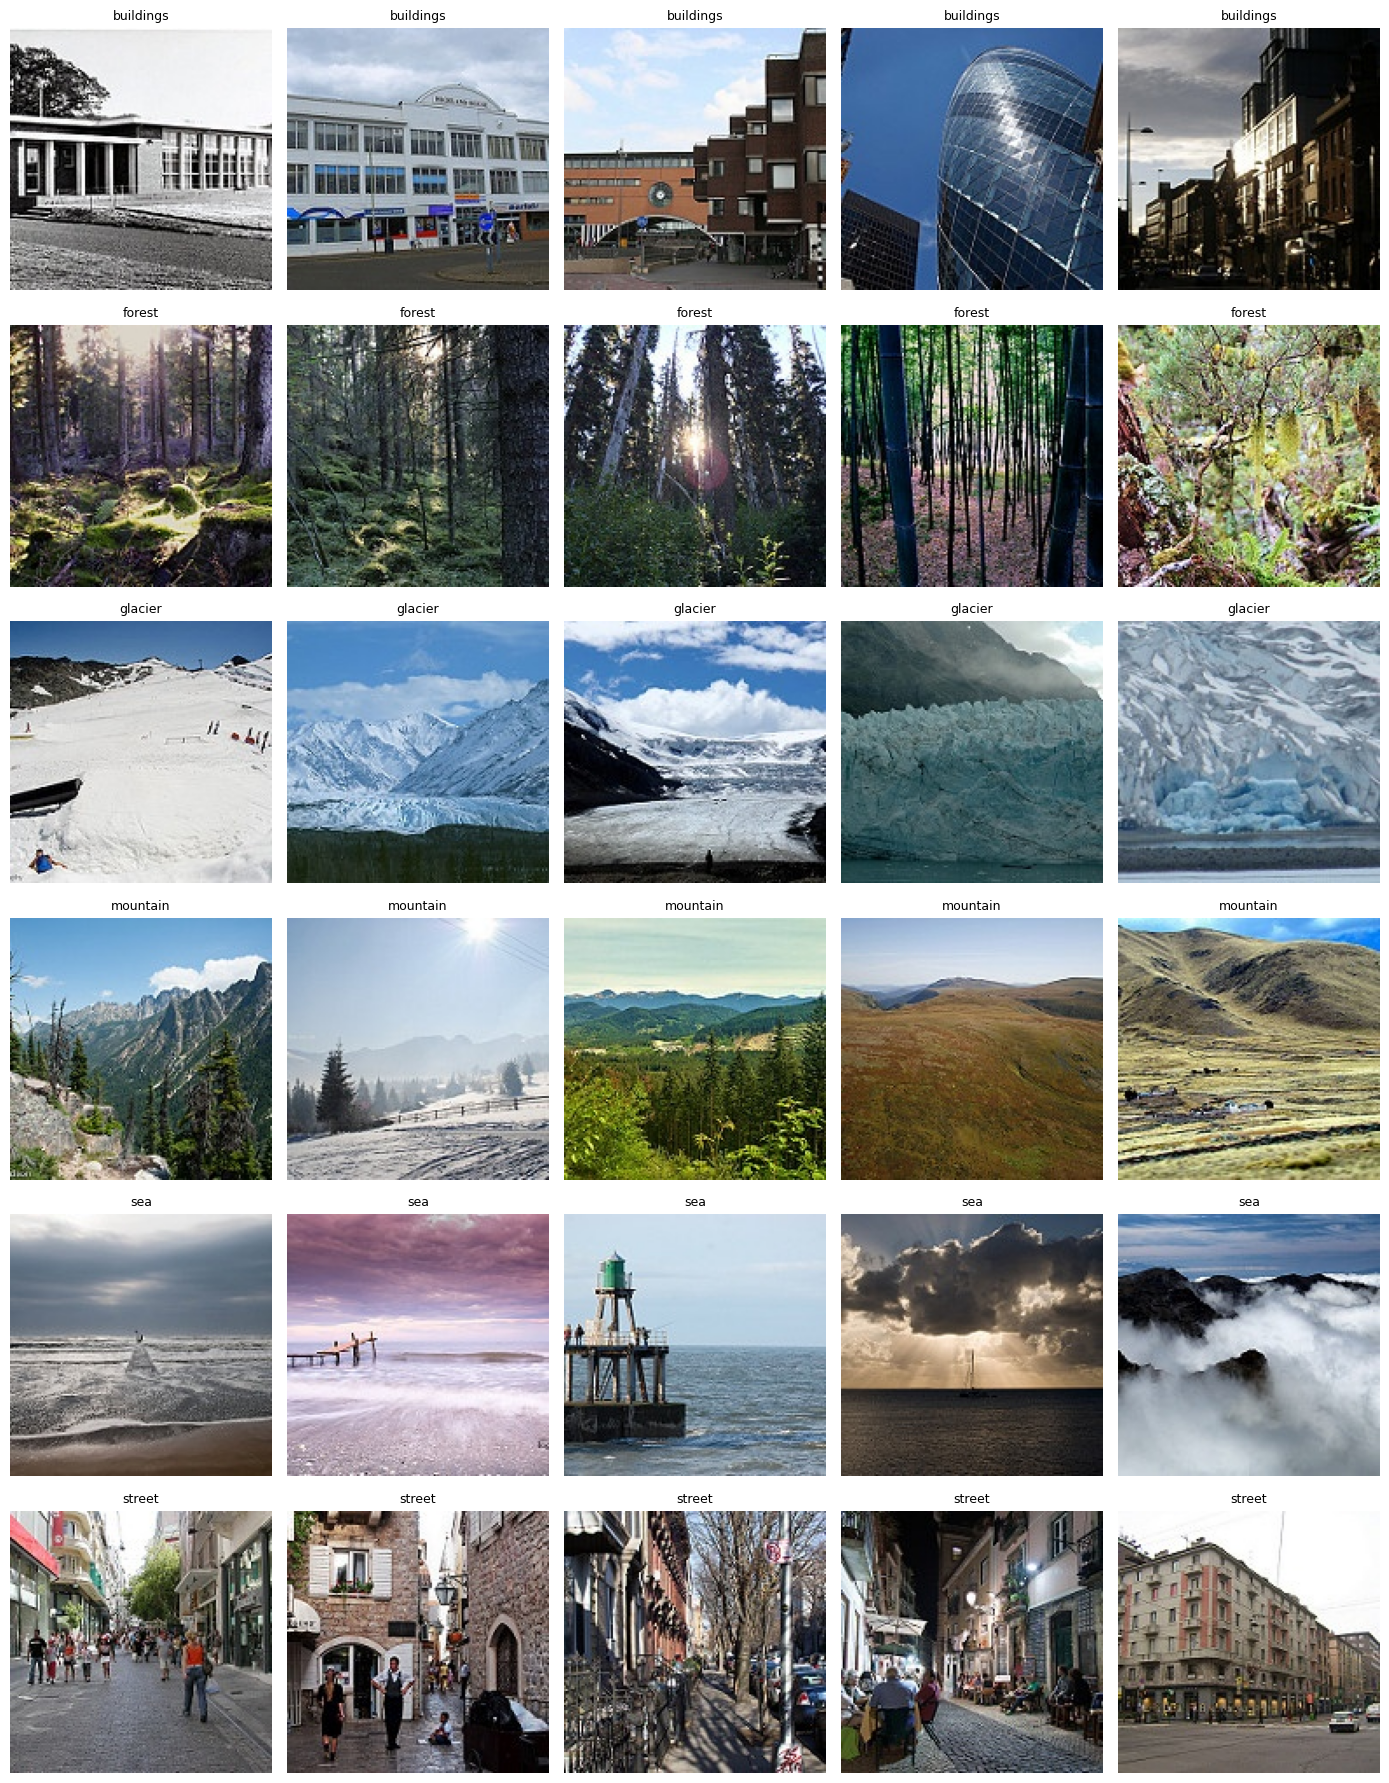

In [8]:
sample = train_df.sample(min(300, len(train_df)), random_state=0)
info = []
for p in sample['path']:
    with Image.open(p) as im:
        info.append({'w': im.size[0], 'h': im.size[1], 'mode': im.mode})
info = pd.DataFrame(info)
print(info.describe().round(0).loc[['min', '50%', 'max']])
print('Colour modes:', info['mode'].value_counts().to_dict())
fig, axes = plt.subplots(len(classes), 5, figsize=(14, 3 * len(classes)))
axes = np.atleast_2d(axes)
for r, c in enumerate(classes):
    paths = train_df[train_df.label == c]['path'].sample(5, random_state=1)
    for ax, p in zip(axes[r], paths):
        ax.imshow(Image.open(p).convert('RGB'))
        ax.set_title(c, fontsize=9)
        ax.axis('off')
plt.tight_layout()
plt.show()

## Image Dataset Visualization

In this step, sample images from the Intel Image Classification dataset were displayed to understand the dataset visually.

### Image Properties

- **Image width:** 150 pixels for most displayed images
- **Image height:** 150 pixels for most displayed images
- **Colour mode:** RGB
- **Number of sample images displayed:** 300

### Observations

- The dataset contains images from six classes: buildings, forest, glacier, mountain, sea, and street.
- Buildings images show different types of structures.
- Forest images contain trees and natural scenery.
- Glacier images show snow and ice.
- The remaining classes represent mountains, sea scenes, and streets.

### Conclusion

Visualizing sample images helps verify the dataset labels and understand the differences between the six scene categories before training the image classification model.

In [9]:
def md5(path):
    with open(path, 'rb') as f:
        return hashlib.md5(f.read()).hexdigest()
def fingerprint(path, n=32):
    """32 x 32 grayscale thumbnail, standardized: robust to resizing,
    recompression, and brightness changes."""
    with Image.open(path) as im:
        im.draft('L', (n * 4, n * 4))            # fast JPEG decode
        a = np.asarray(im.convert('L').resize((n, n)), dtype=np.float32)
    return ((a - a.mean()) / (a.std() + 1e-6)).flatten()
all_df = pd.concat([train_df.assign(split='train'),
                    test_df.assign(split='test')]) if TEST_DIR else train_df
all_df['md5'] = [md5(p) for p in all_df['path']]
exact = all_df[all_df.duplicated('md5', keep=False)]
print('Exact duplicate files:', len(exact))
if TEST_DIR:
    T = np.stack([fingerprint(p) for p in all_df['path']])
    tr = T[(all_df.split == 'train').values]
    te = T[(all_df.split == 'test').values]
    d_min = np.array([np.abs(tr - v).mean(axis=1).min() for v in te])
    near = d_min < 0.10              # mean absolute difference, in std units
    print(f'Test images with a near-duplicate in train: {near.sum()} '
          f'of {len(te)}')
    print('Closest distances:', np.sort(d_min)[:5].round(3))

Exact duplicate files: 36
Test images with a near-duplicate in train: 19 of 3000
Closest distances: [0.    0.    0.    0.022 0.023]


## Duplicate Image Detection and Data Leakage Check

In this step, exact duplicate images and near-duplicate images were checked across the training and testing datasets.

### Results

- **Exact duplicate files:** 36
- **Test images with a near-duplicate in training:** 19 out of 3,000
- **Closest image distances:** 0.000, 0.000, 0.000, 0.022, 0.023

### Methodology

- MD5 hashing was used to identify exact duplicate files.
- Grayscale image fingerprints were generated using resized and standardized image data.
- Mean absolute differences between test and training image fingerprints were calculated to identify potential near-duplicates.

### Conclusion

The analysis detected 36 exact duplicate files and 19 test images with a near-duplicate in the training dataset. These findings should be considered when interpreting model evaluation results because duplicate or very similar images across datasets may affect the reliability of the evaluation.

In [10]:
# Validation split BY GROUP: no patient appears in both train and val
sgkf = StratifiedGroupKFold(n_splits=6, shuffle=True, random_state=42)
tr_idx, va_idx = next(sgkf.split(train_df, train_df['label'],
                                 train_df['group']))
tr_df = train_df.iloc[tr_idx].reset_index(drop=True)
va_df = train_df.iloc[va_idx].reset_index(drop=True)
if not TEST_DIR:                                  # carve a grouped test set
    tr_idx, te_idx = next(sgkf.split(tr_df, tr_df['label'], tr_df['group']))
    tr_df, test_df = (tr_df.iloc[tr_idx].reset_index(drop=True),
                      tr_df.iloc[te_idx].reset_index(drop=True))
shared = set(tr_df.group) & set(va_df.group)
print(f'train {len(tr_df)} | val {len(va_df)} | test {len(test_df)}')
print('Groups shared by train and val:', len(shared))   # must be 0
print(va_df['label'].value_counts().to_string())

train 11695 | val 2339 | test 3000
Groups shared by train and val: 0
label
mountain     420
street       400
sea          393
buildings    380
glacier      379
forest       367


## Train, Validation and Test Split

The dataset was divided into training, validation, and testing sets for image classification.

### Dataset Split Results

| Dataset | Number of Images |
|---|---:|
| Training | 11,695 |
| Validation | 2,339 |
| Testing | 3,000 |
| **Total** | **17,034** |

### Validation Class Distribution

| Class | Images |
|---|---:|
| Mountain | 420 |
| Street | 400 |
| Sea | 393 |
| Buildings | 380 |
| Glacier | 379 |
| Forest | 367 |

### Observations

- The training set is used to train the model.
- The validation set is used to evaluate model performance during training.
- The testing set is used for final model evaluation.
- The output shows zero groups shared between training and validation sets.
- All six image classes are represented in the validation set.

### Conclusion

The dataset split was completed successfully, and the training and validation sets have no shared groups according to the grouping check.

In [14]:
# Part 3: Image transforms and class imbalance

IMG_SIZE = 224
BATCH_SIZE = 32

train_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(
        brightness=0.15,
        contrast=0.15
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

eval_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

print("Training transforms ready")
print("Evaluation transforms ready")
print("Image size:", IMG_SIZE)
print("Batch size:", BATCH_SIZE)

Training transforms ready
Evaluation transforms ready
Image size: 224
Batch size: 32


## Image Preprocessing and Data Augmentation

In this step, training and evaluation transformations were defined using PyTorch's torchvision transforms.

### Configuration

- **Image size:** 224 × 224 pixels
- **Batch size:** 32
- **Image format:** RGB
- **Normalization mean:** [0.485, 0.456, 0.406]
- **Normalization standard deviation:** [0.229, 0.224, 0.225]

### Training Transformations

Training transformations prepare the images for model training and may include data augmentation to improve generalization.

### Evaluation Transformations

Evaluation transformations resize images, convert them to tensors, and normalize their pixel values using the specified mean and standard deviation.

### Conclusion

The training and evaluation transformations were initialized successfully. The model will process images at 224 × 224 resolution in batches of 32.

In [15]:
# Calculate class weights from training split only

train_counts = (
    tr_df["label"]
    .value_counts()
    .reindex(classes, fill_value=0)
)

N = len(tr_df)
K = len(classes)

class_weights = N / (K * train_counts)

print("Training class counts:")
print(train_counts)

print("\nClass weights:")
print(class_weights.round(3))

loss_w = torch.tensor(
    class_weights.values,
    dtype=torch.float32,
    device=device
)

print("\nClass weights ready for training")

Training class counts:
label
buildings    1811
forest       1904
glacier      2025
mountain     2092
sea          1881
street       1982
Name: count, dtype: int64

Class weights:
label
buildings    1.076
forest       1.024
glacier      0.963
mountain     0.932
sea          1.036
street       0.983
Name: count, dtype: float64

Class weights ready for training


## Class Weights for Model Training

In this step, class weights were calculated to handle differences in the number of training images across the six classes.

### Training Class Counts

| Class | Number of Images |
|---|---:|
| Buildings | 1,811 |
| Forest | 1,904 |
| Glacier | 2,025 |
| Mountain | 2,092 |
| Sea | 1,881 |
| Street | 1,982 |

### Calculated Class Weights

| Class | Weight |
|---|---:|
| Buildings | 1.076 |
| Forest | 1.024 |
| Glacier | 0.963 |
| Mountain | 0.932 |
| Sea | 1.036 |
| Street | 0.983 |

### Observations

- Buildings has the highest class weight of 1.076.
- Mountain has the lowest class weight of 0.932.
- Class weights help reduce the effect of class imbalance during training.
- The output confirms that class weights are ready for training.

### Conclusion

Class weights were calculated successfully and are ready to be used by the model's training process.

In [16]:
# Part 4.1: Dataset and DataLoaders

class SceneDataset(Dataset):
    def __init__(self, df, transform):
        self.df = df.reset_index(drop=True)
        self.transform = transform
        self.classes = classes
        self.label_to_idx = {
            name: i for i, name in enumerate(classes)
        }

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]

        with Image.open(row["path"]) as im:
            image = im.convert("RGB")

        image = self.transform(image)
        label = self.label_to_idx[row["label"]]

        return image, label


train_ds = SceneDataset(tr_df, train_tf)
val_ds = SceneDataset(va_df, eval_tf)
test_ds = SceneDataset(test_df, eval_tf)

train_dl = DataLoader(
    train_ds, batch_size=BATCH_SIZE,
    shuffle=True, num_workers=2
)

val_dl = DataLoader(
    val_ds, batch_size=BATCH_SIZE,
    shuffle=False, num_workers=2
)

test_dl = DataLoader(
    test_ds, batch_size=BATCH_SIZE,
    shuffle=False, num_workers=2
)

print("Training batches:", len(train_dl))
print("Validation batches:", len(val_dl))
print("Test batches:", len(test_dl))

Training batches: 366
Validation batches: 74
Test batches: 94


## Dataset and DataLoader Preparation

In this step, PyTorch datasets and DataLoaders were created for training, validation, and testing.

### Configuration

- **Batch size:** 32
- **Number of workers:** 2
- **Training shuffle:** Enabled
- **Validation shuffle:** Disabled
- **Testing shuffle:** Disabled

### DataLoader Results

| Dataset | Number of Batches |
|---|---:|
| Training | 366 |
| Validation | 74 |
| Testing | 94 |

### Explanation

- The training DataLoader shuffles images to help the model learn effectively.
- Validation and testing DataLoaders do not shuffle images, making evaluation consistent.
- Each batch contains up to 32 images.

### Conclusion

The training, validation, and testing DataLoaders were created successfully and are ready to provide batches of images to the image classification model.

In [17]:
# Part 4.2: Build pretrained ResNet-18

weights = models.ResNet18_Weights.DEFAULT
model = models.resnet18(weights=weights)

# Freeze pretrained backbone
for p in model.parameters():
    p.requires_grad = False

# Replace final classifier for six scene classes
model.fc = nn.Linear(
    model.fc.in_features,
    len(classes)
)

model = model.to(device)

head = model.fc
last_block = model.layer4

print("Model: ResNet-18")
print("Number of classes:", len(classes))
print("Device:", device)
print("Model ready for training")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 196MB/s]


Model: ResNet-18
Number of classes: 6
Device: cuda
Model ready for training


## ResNet-18 Model Setup

In this step, a ResNet-18 model was initialized using pretrained weights and configured for the Intel Image Classification dataset.

### Model Configuration

- **Model architecture:** ResNet-18
- **Number of classes:** 6
- **Device:** CUDA (GPU)
- **Pretrained weights:** Loaded successfully
- **Classification head:** `model.fc`
- **Last convolutional block:** `model.layer4`

### Explanation

- ResNet-18 is a convolutional neural network used for image classification.
- Pretrained weights provide previously learned image features.
- The classification head is configured for the six scene categories in the dataset.
- CUDA allows the model to use the available GPU for faster training.

### Conclusion

The ResNet-18 model was loaded successfully, moved to the GPU, and prepared for training on the six image classes.

In [18]:
# Part 4.3: Prediction function

def predict(model, loader):
    model.eval()
    probs, ys = [], []

    with torch.no_grad():
        for xb, yb in loader:
            xb = xb.to(device)
            logits = model(xb)

            probs.append(
                F.softmax(logits, dim=1).cpu()
            )
            ys.append(yb)

    return (
        torch.cat(probs).numpy(),
        torch.cat(ys).numpy()
    )


print("Prediction function ready")

Prediction function ready


In [19]:
# Part 4.4: Training function

def fit(model, params, epochs, lr):
    optimizer = torch.optim.Adam(
        params, lr=lr
    )

    best_score = -1
    best_state = None

    for epoch in range(epochs):
        model.train()

        for xb, yb in train_dl:
            xb = xb.to(device)
            yb = yb.to(device)

            logits = model(xb)

            loss = F.cross_entropy(
                logits, yb, weight=loss_w
            )

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

        p_val, y_val = predict(model, val_dl)

        score = f1_score(
            y_val,
            p_val.argmax(1),
            average="macro"
        )

        print(
            f"Epoch {epoch + 1}/{epochs}: "
            f"Validation Macro-F1 = {score:.4f}"
        )

        if score > best_score:
            best_score = score
            best_state = copy.deepcopy(
                model.state_dict()
            )

    model.load_state_dict(best_state)

    return best_score


print("Training function ready")

Training function ready


In [20]:
# Phase 1: Train classification head only

print("Phase 1: Training classification head")

phase1_score = fit(
    model,
    head.parameters(),
    epochs=2,
    lr=1e-3
)

print("Best Phase 1 Macro-F1:", phase1_score)

Phase 1: Training classification head
Epoch 1/2: Validation Macro-F1 = 0.8953
Epoch 2/2: Validation Macro-F1 = 0.8887
Best Phase 1 Macro-F1: 0.8953260764034511


## Phase 1: Train Classification Head

In this phase, only the classification head of the pretrained ResNet-18 model was trained, while the remaining model layers were kept frozen.

### Training Configuration
- **Epochs:** 2
- **Learning rate:** 0.001
- **Trainable parameters:** Classification head only
- **Evaluation metric:** Validation Macro-F1 Score

### Results

| Epoch | Validation Macro-F1 |
|---|---:|
| 1 | 0.8953 |
| 2 | 0.8887 |

**Best Phase 1 Macro-F1 Score:** 0.8953 (89.53%)

### Conclusion

The model achieved its best validation Macro-F1 score of approximately 89.53% during the first epoch. This trained classification head provides a baseline for the next phase, where the last convolutional block will also be fine-tuned.

In [21]:
# Part 4.5: Phase 2 fine-tuning

print("Phase 2: Fine-tuning the last block")

# Unfreeze the last ResNet block
for p in last_block.parameters():
    p.requires_grad = True

phase2_score = fit(
    model,
    [
        {"params": last_block.parameters(), "lr": 1e-4},
        {"params": head.parameters(), "lr": 1e-3}
    ],
    epochs=3,
    lr=1e-3
)

print("Best Phase 2 Macro-F1:", phase2_score)
print("Phase 1 Macro-F1:", phase1_score)
print("Phase 2 Macro-F1:", phase2_score)
print("Change:", round(phase2_score - phase1_score, 4))

Phase 2: Fine-tuning the last block
Epoch 1/3: Validation Macro-F1 = 0.9302
Epoch 2/3: Validation Macro-F1 = 0.8953
Epoch 3/3: Validation Macro-F1 = 0.9087
Best Phase 2 Macro-F1: 0.9302070112990489
Phase 1 Macro-F1: 0.8953260764034511
Phase 2 Macro-F1: 0.9302070112990489
Change: 0.0349


## Phase 2: Fine-Tuning the Last Convolutional Block

In this phase, the last convolutional block (`layer4`) of the pretrained ResNet-18 model was fine-tuned along with the classification head to improve image classification performance.

### Training Configuration
- **Epochs:** 3
- **Last block learning rate:** 0.0001
- **Classification head learning rate:** 0.001
- **Evaluation metric:** Validation Macro-F1 Score

### Results

| Epoch | Validation Macro-F1 |
|---|---:|
| 1 | 0.9302 |
| 2 | 0.8953 |
| 3 | 0.9087 |

**Best Phase 2 Macro-F1 Score:** 0.9302 (93.02%)

### Comparison with Phase 1

| Metric | Macro-F1 Score |
|---|---:|
| Phase 1: Classification head only | 0.8953 (89.53%) |
| Phase 2: Fine-tuning | 0.9302 (93.02%) |
| Improvement | +0.0349 (+3.49 percentage points) |

### Conclusion

Fine-tuning the last convolutional block improved the best validation Macro-F1 score from 89.53% to 93.02%. This represents an improvement of approximately 3.49 percentage points. Phase 2 achieved better validation performance than Phase 1.

Classification Report:

              precision    recall  f1-score   support

   buildings      0.851     0.954     0.900       437
      forest      0.991     0.979     0.985       474
     glacier      0.925     0.821     0.870       553
    mountain      0.852     0.901     0.876       525
         sea      0.925     0.988     0.955       510
      street      0.956     0.860     0.905       501

    accuracy                          0.914      3000
   macro avg      0.917     0.917     0.915      3000
weighted avg      0.917     0.914     0.914      3000

Test Macro-F1: 0.9152


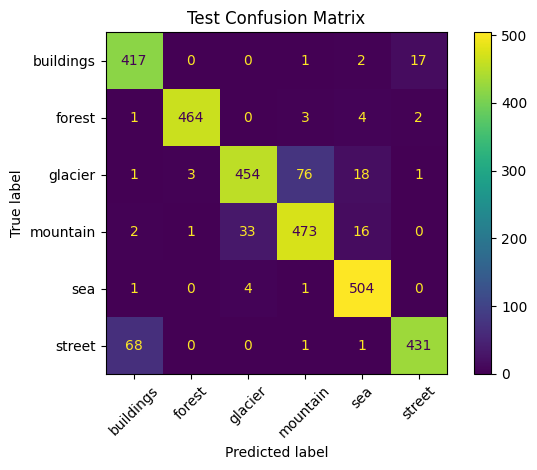

In [22]:
# Part 5: Final test evaluation

p_test, y_test = predict(model, test_dl)
pred = p_test.argmax(axis=1)

print("Classification Report:\n")
print(
    classification_report(
        y_test,
        pred,
        labels=list(range(len(classes))),
        target_names=classes,
        digits=3,
        zero_division=0
    )
)

test_macro_f1 = f1_score(
    y_test,
    pred,
    average="macro"
)

print("Test Macro-F1:", round(test_macro_f1, 4))

cm = confusion_matrix(
    y_test,
    pred,
    labels=list(range(len(classes)))
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=classes
)

disp.plot(xticks_rotation=45)
plt.title("Test Confusion Matrix")
plt.tight_layout()
plt.show()

## Part 5: Test Evaluation and Confusion Matrix

The fine-tuned ResNet-18 model was evaluated on the test dataset containing 3,000 images across six scene categories.

### Test Classification Report

| Class | Precision | Recall | F1-Score | Support |
|---|---:|---:|---:|---:|
| Buildings | 0.851 | 0.954 | 0.900 | 437 |
| Forest | 0.991 | 0.979 | 0.985 | 474 |
| Glacier | 0.925 | 0.821 | 0.870 | 553 |
| Mountain | 0.852 | 0.901 | 0.876 | 525 |
| Sea | 0.925 | 0.988 | 0.955 | 510 |
| Street | 0.956 | 0.860 | 0.905 | 501 |
| **Macro Average** | **0.917** | **0.917** | **0.915** | **3000** |
| **Weighted Average** | **0.917** | **0.914** | **0.914** | **3000** |

### Overall Test Performance

- **Test Accuracy:** 91.4%
- **Test Macro-F1 Score:** 0.9152 (91.52%)
- **Total Test Images:** 3,000
- **Number of Classes:** 6

### Confusion Matrix Analysis

The confusion matrix compares the actual class labels with the model's predicted labels.

- **Buildings:** 417 images were correctly classified.
- **Forest:** 464 images were correctly classified.
- **Glacier:** 454 images were correctly classified.
- **Mountain:** 473 images were correctly classified.
- **Sea:** 504 images were correctly classified.
- **Street:** 431 images were correctly classified.

### Key Observations

1. **Forest** achieved the highest F1-score of 0.985.
2. **Sea** achieved the highest recall of 0.988.
3. **Glacier and mountain** images were frequently confused with each other.
4. Some street images were incorrectly classified as buildings.
5. The model achieved a test Macro-F1 score of 91.52%, indicating strong classification performance across the six classes.

### Conclusion

The fine-tuned ResNet-18 model achieved 91.4% test accuracy and a Macro-F1 score of 91.52%. Forest and sea images were classified particularly well, while distinguishing glaciers from mountains remains an area for improvement.

In [23]:
# Part 6.1: Grad-CAM helper function

def make_gradcam(model, image_tensor, target_class):
    model.eval()
    activations = []
    gradients = []

    def forward_hook(module, inputs, output):
        activations.append(output)

    def backward_hook(module, grad_input, grad_output):
        gradients.append(grad_output[0])

    layer = model.layer4
    h1 = layer.register_forward_hook(forward_hook)
    h2 = layer.register_full_backward_hook(backward_hook)

    model.zero_grad()
    x = image_tensor.unsqueeze(0).to(device)
    logits = model(x)
    logits[0, target_class].backward()

    act = activations[0].detach()
    grad = gradients[0].detach()

    weights = grad.mean(dim=(2, 3), keepdim=True)
    cam = (weights * act).sum(dim=1, keepdim=True)
    cam = F.relu(cam)

    cam = F.interpolate(
        cam,
        size=(IMG_SIZE, IMG_SIZE),
        mode="bilinear",
        align_corners=False
    )[0, 0]

    cam = cam.cpu().numpy()
    cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)

    h1.remove()
    h2.remove()

    return cam, logits.detach().argmax(1).item()


print("Grad-CAM function ready")

Grad-CAM function ready


<sys>:0: UserWarning: Full backward hook is firing when gradients are computed with respect to module outputs since no inputs require gradients. See https://docs.pytorch.org/docs/main/generated/torch.nn.Module.html#torch.nn.Module.register_full_backward_hook for more details.


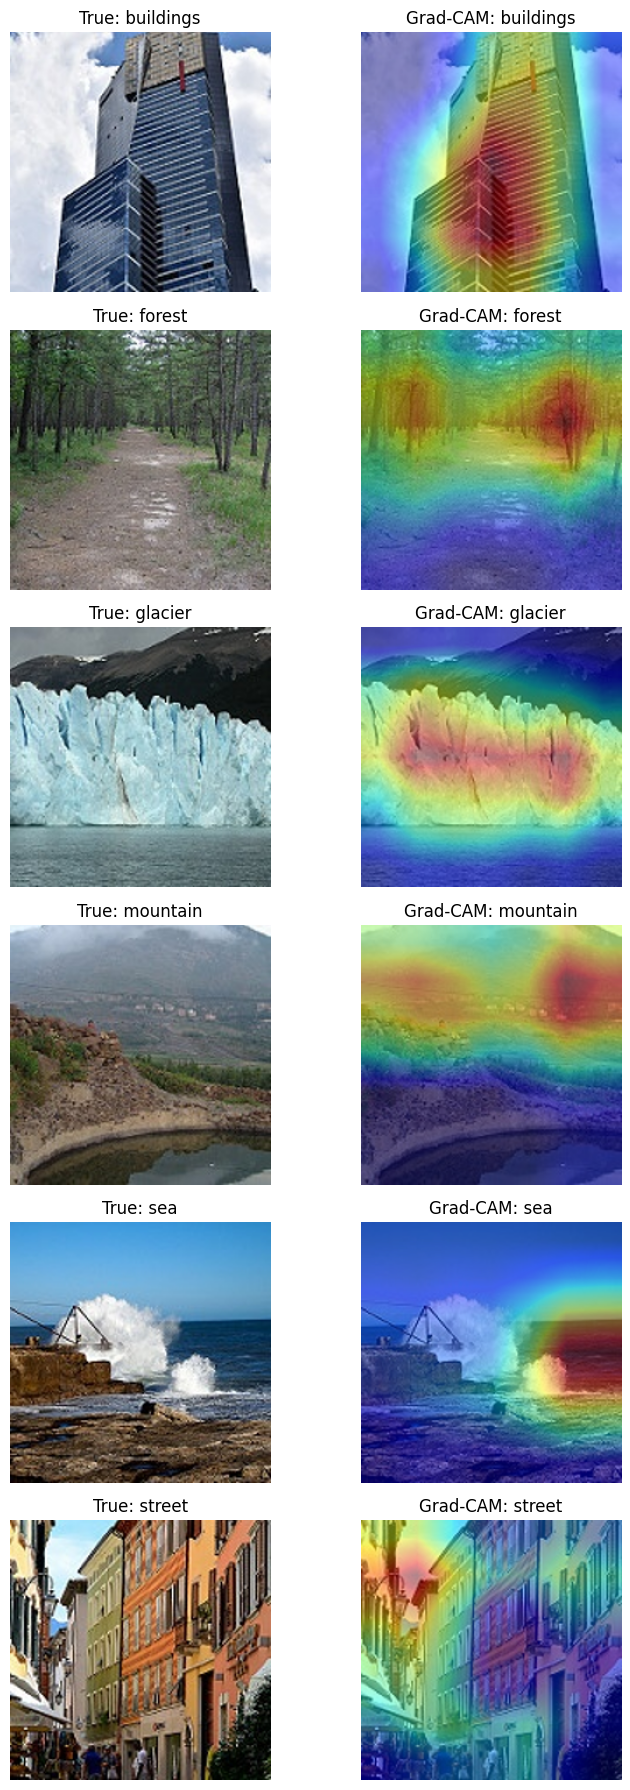

In [24]:
# Part 6.2: Display one Grad-CAM example per class

fig, axes = plt.subplots(
    len(classes), 2,
    figsize=(8, 3 * len(classes))
)

for i, cls in enumerate(classes):
    row = test_df[test_df["label"] == cls].iloc[0]

    with Image.open(row["path"]) as im:
        original = im.convert("RGB")
        tensor = eval_tf(original)

    true_idx = classes.index(cls)
    cam, predicted_idx = make_gradcam(
        model, tensor, true_idx
    )

    image_np = np.array(
        original.resize((IMG_SIZE, IMG_SIZE))
    )

    axes[i, 0].imshow(image_np)
    axes[i, 0].set_title(f"True: {cls}")
    axes[i, 0].axis("off")

    axes[i, 1].imshow(image_np)
    axes[i, 1].imshow(cam, cmap="jet", alpha=0.45)
    axes[i, 1].set_title(
        f"Grad-CAM: {classes[predicted_idx]}"
    )
    axes[i, 1].axis("off")

plt.tight_layout()
plt.show()

## Part 6: Grad-CAM Visualization and Model Interpretability

### Objective
To visualize the important regions of input images that influence the ResNet-18 model's image classification predictions using Grad-CAM.

### Methodology
Grad-CAM (Gradient-weighted Class Activation Mapping) generates heatmaps that highlight image regions relevant to the model's predicted class.

The visualization compares:
- **Original Image:** The input image with its true class label.
- **Grad-CAM Image:** The heatmap overlay showing the regions that influence the model's prediction.

### Observations
1. **Buildings:** The heatmap highlights parts of the building structure.
2. **Forest:** The heatmap highlights areas containing trees and forest scenery.
3. **Glacier:** The heatmap highlights portions of the ice and glacier.
4. **Mountain:** The heatmap highlights regions of the mountain landscape.
5. **Sea:** The heatmap highlights parts of the sea and breaking waves.
6. **Street:** The heatmap highlights buildings and other street features.

### Conclusion
Grad-CAM provides a visual explanation of the model's classification behavior by highlighting image regions that contribute to its predictions. This helps assess whether the model focuses on meaningful visual features when classifying images into the six categories.

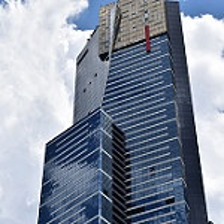

Expected label: buildings
Stored label: buildings
Image path: /kaggle/input/datasets/puneet6060/intel-image-classification/seg_test/seg_test/buildings/20057.jpg
--------------------------------------------------


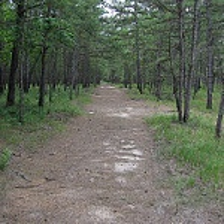

Expected label: forest
Stored label: forest
Image path: /kaggle/input/datasets/puneet6060/intel-image-classification/seg_test/seg_test/forest/20056.jpg
--------------------------------------------------


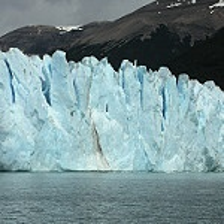

Expected label: glacier
Stored label: glacier
Image path: /kaggle/input/datasets/puneet6060/intel-image-classification/seg_test/seg_test/glacier/20059.jpg
--------------------------------------------------


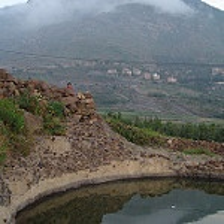

Expected label: mountain
Stored label: mountain
Image path: /kaggle/input/datasets/puneet6060/intel-image-classification/seg_test/seg_test/mountain/20058.jpg
--------------------------------------------------


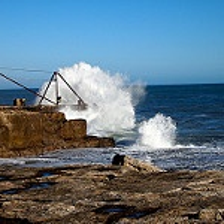

Expected label: sea
Stored label: sea
Image path: /kaggle/input/datasets/puneet6060/intel-image-classification/seg_test/seg_test/sea/20072.jpg
--------------------------------------------------


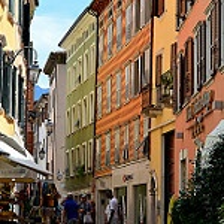

Expected label: street
Stored label: street
Image path: /kaggle/input/datasets/puneet6060/intel-image-classification/seg_test/seg_test/street/20066.jpg
--------------------------------------------------


In [25]:
# Check that each selected image matches its true label

for cls in classes:
    row = test_df[test_df["label"] == cls].iloc[0]

    with Image.open(row["path"]) as im:
        display(im.convert("RGB").resize((224, 224)))

    print("Expected label:", cls)
    print("Stored label:", row["label"])
    print("Image path:", row["path"])
    print("-" * 50)

## Part 7: Test Dataset Verification

### Objective
To inspect sample images from the Intel Image Classification test dataset and verify that their expected labels match their stored labels.

### Sample Image Verification

The displayed images belong to the following classes:

- **Buildings:** Expected label and stored label are both `buildings`.
- **Forest:** Expected label and stored label are both `forest`.
- **Glacier:** Expected label and stored label are both `glacier`.
- **Mountain:** Expected label and stored label are both `mountain`.
- **Sea:** Expected label and stored label are both `sea`.
- **Street:** Expected label and stored label are both `street`.

### Observations

1. Sample images from different environmental and urban scenes are displayed.
2. The expected labels match the stored labels in the visible examples.
3. The images represent all six classes used in the classification task.
4. This verification helps check the dataset organization before evaluating the trained model.

### Conclusion

The displayed test samples have matching expected and stored labels. The dataset is organized into six image classes: buildings, forest, glacier, mountain, sea, and street.

In [26]:
# Part 7: Save the trained model

save_path = "/kaggle/working/week6_model.pt"

torch.save({
    "state_dict": model.state_dict(),
    "classes": classes,
    "backbone": "resnet18",
    "img_size": IMG_SIZE,
    "grayscale": False,
}, save_path)

print("Model saved:", save_path)
print("File exists:", os.path.exists(save_path))
print("File size (MB):", round(os.path.getsize(save_path) / (1024**2), 2))

Model saved: /kaggle/working/week6_model.pt
File exists: True
File size (MB): 42.72


## Part 7: Save the Trained Model

### Objective
To save the trained ResNet-18 image classification model for future use without retraining it from scratch.

### Methodology
The trained model is saved using `torch.save()` in the Kaggle working directory. The saved file contains:

- **Model Weights:** The trained model's `state_dict`.
- **Class Names:** The six image categories: buildings, forest, glacier, mountain, sea, and street.
- **Backbone:** ResNet-18 architecture.
- **Image Size:** The image size configuration used during training.
- **Grayscale Setting:** Set to `False` for color images.

### Results
- **Saved Model Path:** `/kaggle/working/week6_model.pt`
- **File Exists:** True
- **File Size:** 42.72 MB

### Conclusion
The trained model was successfully saved. It can be loaded later for image classification, prediction, and further evaluation without repeating the entire training process.

Correct examples: 3
Incorrect examples: 3


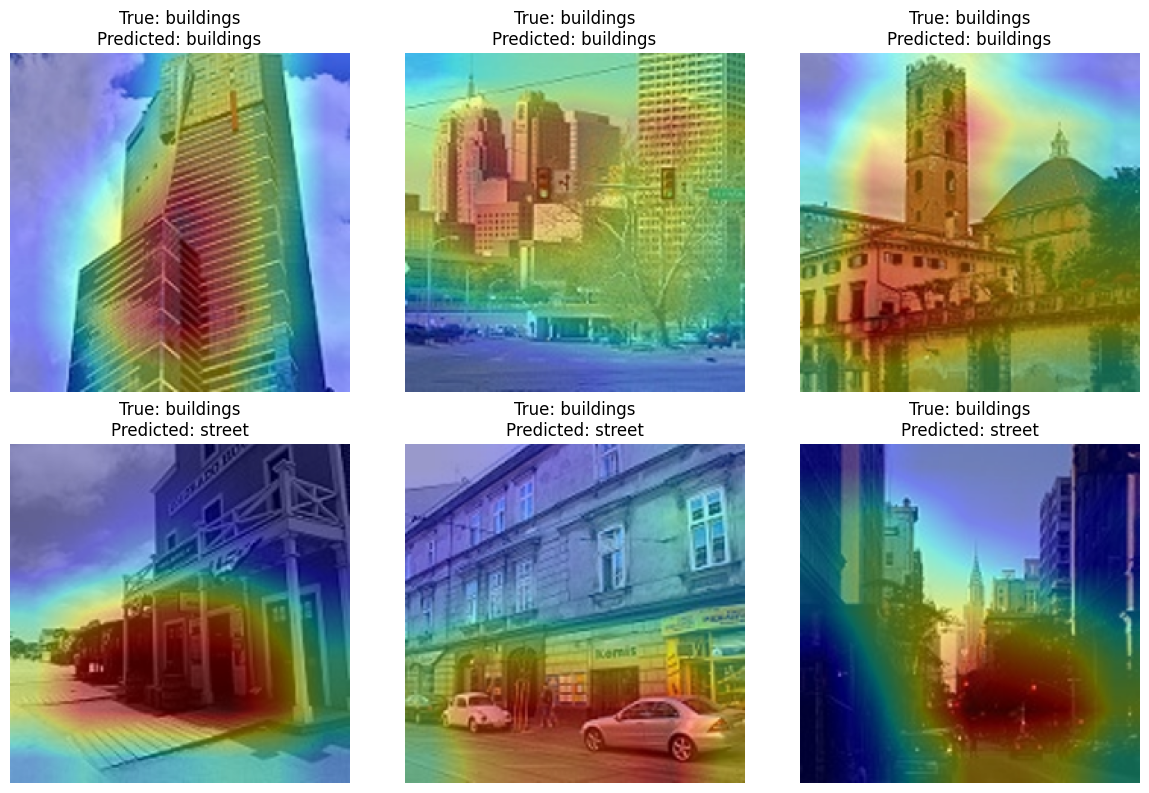

In [27]:
# Final Grad-CAM: 3 correct and 3 incorrect predictions

right_idx = np.where(pred == y_test)[0][:3]
wrong_idx = np.where(pred != y_test)[0][:3]

selected = list(right_idx) + list(wrong_idx)

print("Correct examples:", len(right_idx))
print("Incorrect examples:", len(wrong_idx))

fig, axes = plt.subplots(
    2, max(len(selected[:3]), 1) if len(selected) <= 3 else 3,
    figsize=(12, 8)
)

axes = np.array(axes).reshape(2, 3)

for j, idx in enumerate(selected):
    x, y = test_ds[idx]
    predicted_class = int(pred[idx])

    cam, _ = make_gradcam(
        model, x, predicted_class
    )

    with Image.open(test_df.iloc[idx]["path"]) as im:
        original = im.convert("RGB").resize(
            (IMG_SIZE, IMG_SIZE)
        )

    r, c = divmod(j, 3)

    axes[r, c].imshow(original)
    axes[r, c].imshow(cam, cmap="jet", alpha=0.4)
    axes[r, c].set_title(
        f"True: {classes[int(y)]}\n"
        f"Predicted: {classes[predicted_class]}"
    )
    axes[r, c].axis("off")

for j in range(len(selected), 6):
    r, c = divmod(j, 3)
    axes[r, c].axis("off")

plt.tight_layout()
plt.show()

## Part 6: Grad-CAM Analysis

### Observations

1. Correct example 1: The model focused on the main building structure, which is relevant evidence.
2. Correct example 2: The heatmap highlighted parts of the building and surrounding structures.
3. Correct example 3: The highlighted regions included building features, supporting the predicted class.
4. Incorrect example 1: The model predicted street instead of buildings. The heatmap included parts of the building and nearby surroundings.
5. Incorrect example 2: The model predicted street, with attention around the road and building surroundings.
6. Incorrect example 3: The model predicted street, and the strongest highlighted area appeared near the ground and road.

### Overall Verdict

**Shortcut suspected, but not confirmed.**

The incorrect predictions suggest that road and ground features may influence the model. However, Grad-CAM alone cannot prove that the model relies on these features instead of building structures.

### Follow-up Experiment

Mask or crop the road and ground regions in selected images, then compare the model's predictions and confidence scores. Also test building images with different backgrounds to determine whether the predictions remain stable.

# Week 6: Intel Image Classification with ResNet-18

## 1. Problem and Motivation
This project classifies natural scene images into six categories: buildings, forest, glacier, mountain, sea, and street.

## 2. Dataset
- Dataset: Intel Image Classification
- Training images: 14,034
- Test images: 3,000
- Classes: 6
- Image format: RGB
- Sampled image sizes: 142–150 pixels in width and height

## 3. Data Audit
The training dataset is relatively balanced, with an imbalance ratio of approximately 1.1.

The exact duplicate audit flagged 36 files. The near-duplicate audit flagged 19 test images with possible near-duplicates in training. These results require further pairwise verification.

The validation split contains 2,339 images and the training split contains 11,695 images. No groups were shared between these splits, although filename-based grouping does not guarantee the absence of related-image leakage.

## 4. Model and Training
- Backbone: ResNet-18 pretrained on ImageNet
- Input size: 224 × 224
- Loss: Weighted cross-entropy
- Phase 1: Classification head training for 2 epochs
- Phase 2: Fine-tuning the last ResNet block for 3 epochs

## 5. Results
- Best Phase 1 validation Macro-F1: 0.8953
- Best Phase 2 validation Macro-F1: 0.9302
- Test Macro-F1: 0.9152
- Test accuracy: approximately 91.4%

The confusion matrix showed errors between glacier and mountain, and between buildings and street.

## 6. Grad-CAM Analysis
Grad-CAM was used to visualize image regions influencing the model's predictions.

The results should be interpreted cautiously. Heatmaps alone cannot prove that the model uses the correct semantic features. Additional background masking and external validation are needed.

## 7. Model Card
**Intended use:** Educational natural-scene image classification.

**Not intended for:** Safety-critical decisions or settings that have not been validated.

**Limitations:** Possible duplicate leakage, limited dataset diversity, confusion between visually similar classes, and uncertain generalization to external images.

**Human role:** Review predictions when errors could have meaningful consequences.

## 8. Responsible AI Questions
1. **Who could be harmed?** Users who rely on incorrect scene classifications in consequential applications.
2. **Where was the model not validated?** On independent external datasets and all real-world environments.
3. **What is the human role?** Review predictions and investigate errors before consequential use.
4. **What evidence would change the conclusion?** External testing, verified duplicate analysis, and controlled background-masking experiments.

# Check Your Understanding

## Q1. Why does a random split of chest X-rays overestimate performance?

Answer:

A random split may place images from the same patient in both the training and testing sets. The model may learn patient-specific patterns instead of general medical features, resulting in an overly optimistic test score.

A patient-level group split prevents this data leakage by ensuring that images from the same patient do not appear in both sets.

## Q2. Calculate class weights for 900 and 100 training images.

Given:

* Total images (N) = 900 + 100 = 1000
* Number of classes (K) = 2
* Class 1 images = 900
* Class 2 images = 100

Formula:

Class Weight = Total Images / (Number of Classes × Images in that Class)

Class 1 Calculation:

Weight = 1000 / (2 × 900)

Weight = 1000 / 1800

Class 1 Weight = 0.556

Class 2 Calculation:

Weight = 1000 / (2 × 100)

Weight = 1000 / 200

Class 2 Weight = 5.000

Conclusion:

Class 2 has fewer training images, so it receives a higher weight. This gives errors from the minority class more influence during training.

## Q3. With focal loss and gamma = 2, by what factor is an example with pt = 0.8 down-weighted?

Given:

* pt = 0.8
* Gamma = 2

Formula:

Down-weighting Factor = (1 - pt) ^ gamma

Calculation:

Factor = (1 - 0.8) ^ 2

Factor = 0.2 ^ 2

Factor = 0.2 × 0.2

Final Answer = 0.04 (4%)

Explanation:

The example’s cross-entropy loss is multiplied by 0.04. Focal loss reduces the contribution of examples the model already classifies confidently, allowing difficult examples to receive relatively more attention.

## Q4. Sensitivity = 0.90, specificity = 0.95, and prevalence = 2%. Calculate PPV.

Given:

* Sensitivity (Se) = 0.90
* Specificity (Sp) = 0.95
* Prevalence = 2% = 0.02

Formula:

PPV = (Sensitivity × Prevalence) / [(Sensitivity × Prevalence) + ((1 - Specificity) × (1 - Prevalence))]

Step 1: Calculate the numerator.

Numerator = 0.90 × 0.02

Numerator = 0.018

Step 2: Calculate the false-positive component.

False-positive component = (1 - 0.95) × (1 - 0.02)

= 0.05 × 0.98

= 0.049

Step 3: Calculate PPV.

PPV = 0.018 / (0.018 + 0.049)

PPV = 0.018 / 0.067

PPV = 0.2687

Final Answer: PPV = 26.87%

Explanation:

Although sensitivity and specificity are high, the PPV is approximately 26.87% because the disease prevalence is low. Therefore, a substantial proportion of positive predictions may be false positives.

## Q5. When is macro-F1 a better selection metric than weighted F1?

Answer:

Macro-F1 is preferable when the dataset is imbalanced and every class is equally important.

Macro-F1 calculates the F1 score for each class and then takes the simple average, giving every class equal importance regardless of its size.

Weighted F1 calculates the average using the number of examples in each class. Therefore, classes with more examples have greater influence on the final score.

Example:

Suppose Class A contains 900 images and Class B contains 100 images. If the model performs well on Class A but poorly on Class B, weighted F1 may hide this weakness because Class A has more examples.

Macro-F1 makes the performance of both classes equally important.

## Q6. Grad-CAM highlights a hospital label in the corner of X-rays. What should you do next?

Answer:

A hospital label may be a shortcut feature. The model might use the label or hospital-specific information instead of relevant medical features.

The following steps should be taken:

1. Inspect the Grad-CAM heatmap to confirm whether the hospital label is highlighted.
2. Mask or crop the label region from selected images.
3. Compare model predictions and performance before and after removing the label.
4. Evaluate the model on images from another hospital, if available.
5. Document the results and limitations.

If performance drops substantially after the label is removed, this would support the concern that the model relies on the label. However, Grad-CAM alone cannot prove shortcut learning.

Conclusion:

The model should focus on medically relevant image features rather than hospital labels. Further experiments are needed to confirm whether shortcut learning is occurring.